In [39]:
from pathlib import Path

import pandas as pd

ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / 'pnas_report/data/dataset_graph/reduced_cleaned_transfers_with_players.csv.gz').is_file()
)
DATA_PATH = ROOT / 'pnas_report/data/dataset_graph/reduced_cleaned_transfers_with_players.csv.gz'

data_full = pd.read_csv(DATA_PATH, low_memory=False)
data_full.head()

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur_transfer,player_name,...,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur_player,highest_market_value_in_eur,age_when_transferred
0,1045344,2027-06-30,26/27,200,15,Utrecht,Leverkusen,0.0,5000000.0,Artem Stepanov,...,https://img.a.transfermarkt.technology/portrai...,7.0,1.0,NaN,https://www.transfermarkt.co.uk/artem-stepanov...,NL1,FC Utrecht,5000000.0,5000000.0,19.0
1,1052439,2027-06-30,26/27,209,631,River Plate,Chelsea,0.0,8000000.0,Kendry Páez,...,https://img.a.transfermarkt.technology/portrai...,27.0,2.0,NaN,https://www.transfermarkt.co.uk/kendry-paez/pr...,FR1,RC Strasbourg Alsace,8000000.0,12000000.0,20.0
2,1154876,2027-06-30,26/27,798,39,Excelsior,Mainz,0.0,450000.0,Kasey Bos,...,https://img.a.transfermarkt.technology/portrai...,0.0,0.0,3433.0,https://www.transfermarkt.co.uk/kasey-bos/prof...,L1,1.FSV Mainz 05,450000.0,450000.0,23.0
3,1043003,2027-01-27,26/27,114,405,Besiktas,Aston Villa,0.0,5000000.0,Yasin Özcan,...,https://img.a.transfermarkt.technology/portrai...,20.0,0.0,NaN,https://www.transfermarkt.co.uk/yasin-ozcan/pr...,BE1,RSC Anderlecht,5000000.0,7500000.0,20.0
4,787618,2026-12-31,26/27,1444,46,Racing Club,Inter,0.0,7500000.0,Valentín Carboni,...,https://img.a.transfermarkt.technology/portrai...,3.0,0.0,NaN,https://www.transfermarkt.co.uk/valentin-carbo...,ARG1,Racing Club Asociación Civil de Avellaneda,7500000.0,15000000.0,21.0


In [40]:
import networkx as nx

transfer_counts = (
    data_full.groupby(['from_club_id', 'to_club_id'])
    .size().reset_index(name='weight')
)
graph = nx.from_pandas_edgelist(
    transfer_counts, source='from_club_id', target='to_club_id',
    edge_attr='weight', create_using=nx.DiGraph,
)

club_labels = dict(zip(data_full['from_club_id'], data_full['from_club_name']))
club_labels.update(zip(data_full['to_club_id'], data_full['to_club_name']))
nx.set_node_attributes(graph, club_labels, 'label')

graph

In [41]:
degree_df = pd.DataFrame({
    'in_degree': dict(graph.in_degree()),
    'out_degree': dict(graph.out_degree()),
}).rename_axis('node').reset_index()
degree_df.insert(1, 'club_name', degree_df['node'].map(club_labels))

degree_df.sort_values('in_degree', ascending=False).head(10)

,node,club_name,in_degree,out_degree
43,410,Udinese,160,135
93,252,Genoa,150,137
86,46,Inter,147,151
111,430,Fiorentina,143,131
40,276,Hellas Verona,141,119
94,281,Man City,138,132
80,12,Roma,136,129
119,631,Chelsea,133,123
123,800,Atalanta BC,117,104
108,416,Torino,116,110


In [45]:
network_summary = pd.Series({
    'Number of nodes': graph.number_of_nodes(),
    'Number of directed edges': graph.number_of_edges(),
    'Maximum in-degree': degree_df['in_degree'].max(),
    'Maximum out-degree': degree_df['out_degree'].max(),
    'Mean in-degree': degree_df['in_degree'].mean().round(2),
    'Mean out-degree': degree_df['out_degree'].mean().round(2),
    'Median in-degree': degree_df['in_degree'].median(),
    'Median out-degree': degree_df['out_degree'].median(),
}, name='Value', dtype=object).rename_axis('Statistic').to_frame()

network_summary

,Value
Statistic,
Number of nodes,1265
Number of directed edges,14906
Maximum in-degree,160
Maximum out-degree,151
Mean in-degree,11.78
Mean out-degree,11.78
Median in-degree,2.0
Median out-degree,2.0


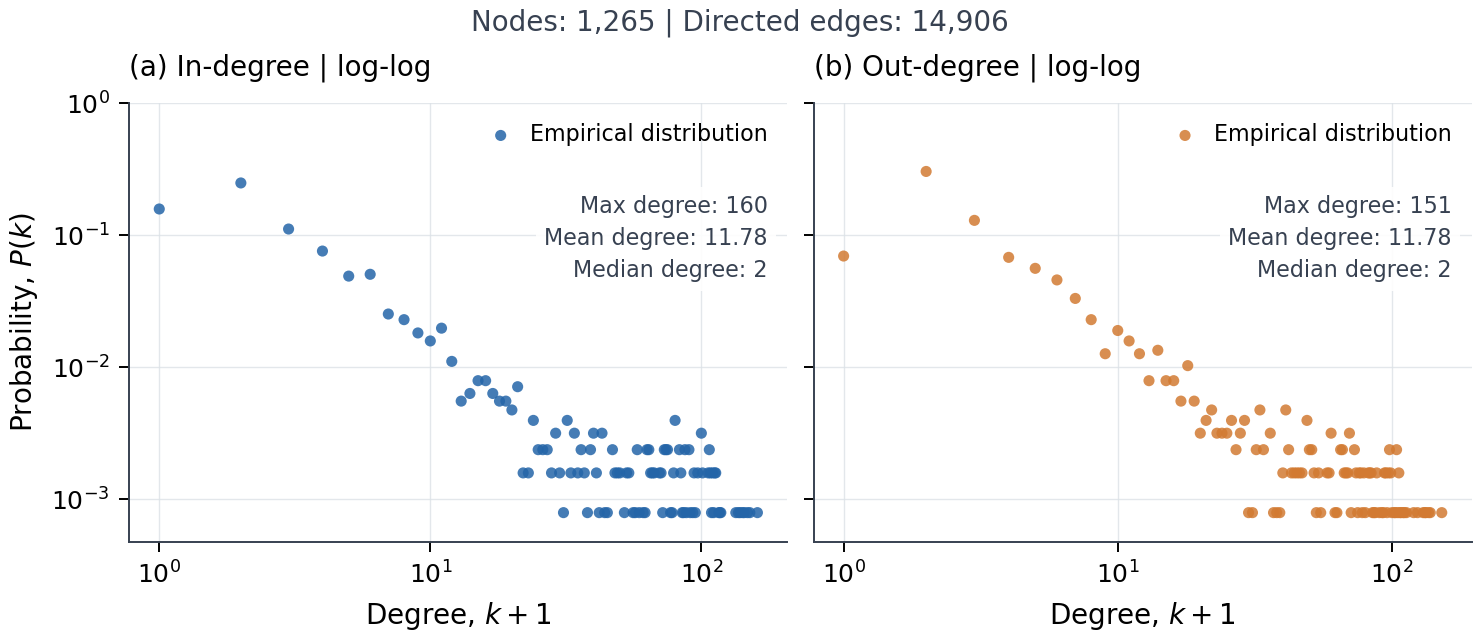

In [5]:
import matplotlib.pyplot as plt

# Straight tails suggest a power law on log-log axes.
with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.labelsize': 10,
    'axes.edgecolor': '#374151',
    'axes.linewidth': 0.7,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.fontsize': 8,
    'figure.dpi': 160,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
    'svg.fonttype': 'none',
}):
    # 1 row, 2 columns side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.2), sharey=True, layout='constrained')
    
    summary = network_summary['Value']
    fig.suptitle(
        f"Nodes: {summary['Number of nodes']:,} | Directed edges: {summary['Number of directed edges']:,}",
        fontsize=10, color='#374151',
    )

    degree_columns = [
        ('in_degree', 'In-degree', '#2465A8'),
        ('out_degree', 'Out-degree', '#D27A32'),
    ]

    for col, (degree_column, title, color) in enumerate(degree_columns):
        probability = degree_df[degree_column].value_counts(normalize=True).sort_index()
        k_plus_one = probability.index.to_numpy() + 1

        ax = axes[col]
        ax.scatter(
            k_plus_one, probability.to_numpy(), s=16, color=color,
            alpha=0.85, edgecolors='none', label='Empirical distribution',
        )
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_ylim(0.6 / len(degree_df), 1)
        ax.set_xlabel(r'Degree, $k + 1$')
        
        if col == 0:
            ax.set_ylabel(r'Probability, $P(k)$')
            
        panel = chr(ord('a') + col)
        ax.set_title(f'({panel}) {title} | log-log', loc='left', pad=10)
        ax.grid(which='major', color='#DCE1E7', linewidth=0.5, alpha=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(which='both', direction='out', width=0.7)
        ax.tick_params(which='minor', bottom=False, left=False)
        ax.legend(loc='upper right', frameon=False, handletextpad=0.3)
        degree_name = title.lower()
        stats_text = (
            f"Max degree: {summary[f'Maximum {degree_name}']:g}\n"
            f"Mean degree: {summary[f'Mean {degree_name}']:.2f}\n"
            f"Median degree: {summary[f'Median {degree_name}']:g}"
        )
        ax.text(
            0.97, 0.79, stats_text, transform=ax.transAxes,
            ha='right', va='top', fontsize=8, color='#374151', linespacing=1.5,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9, 'pad': 3},
        )

    plt.show()

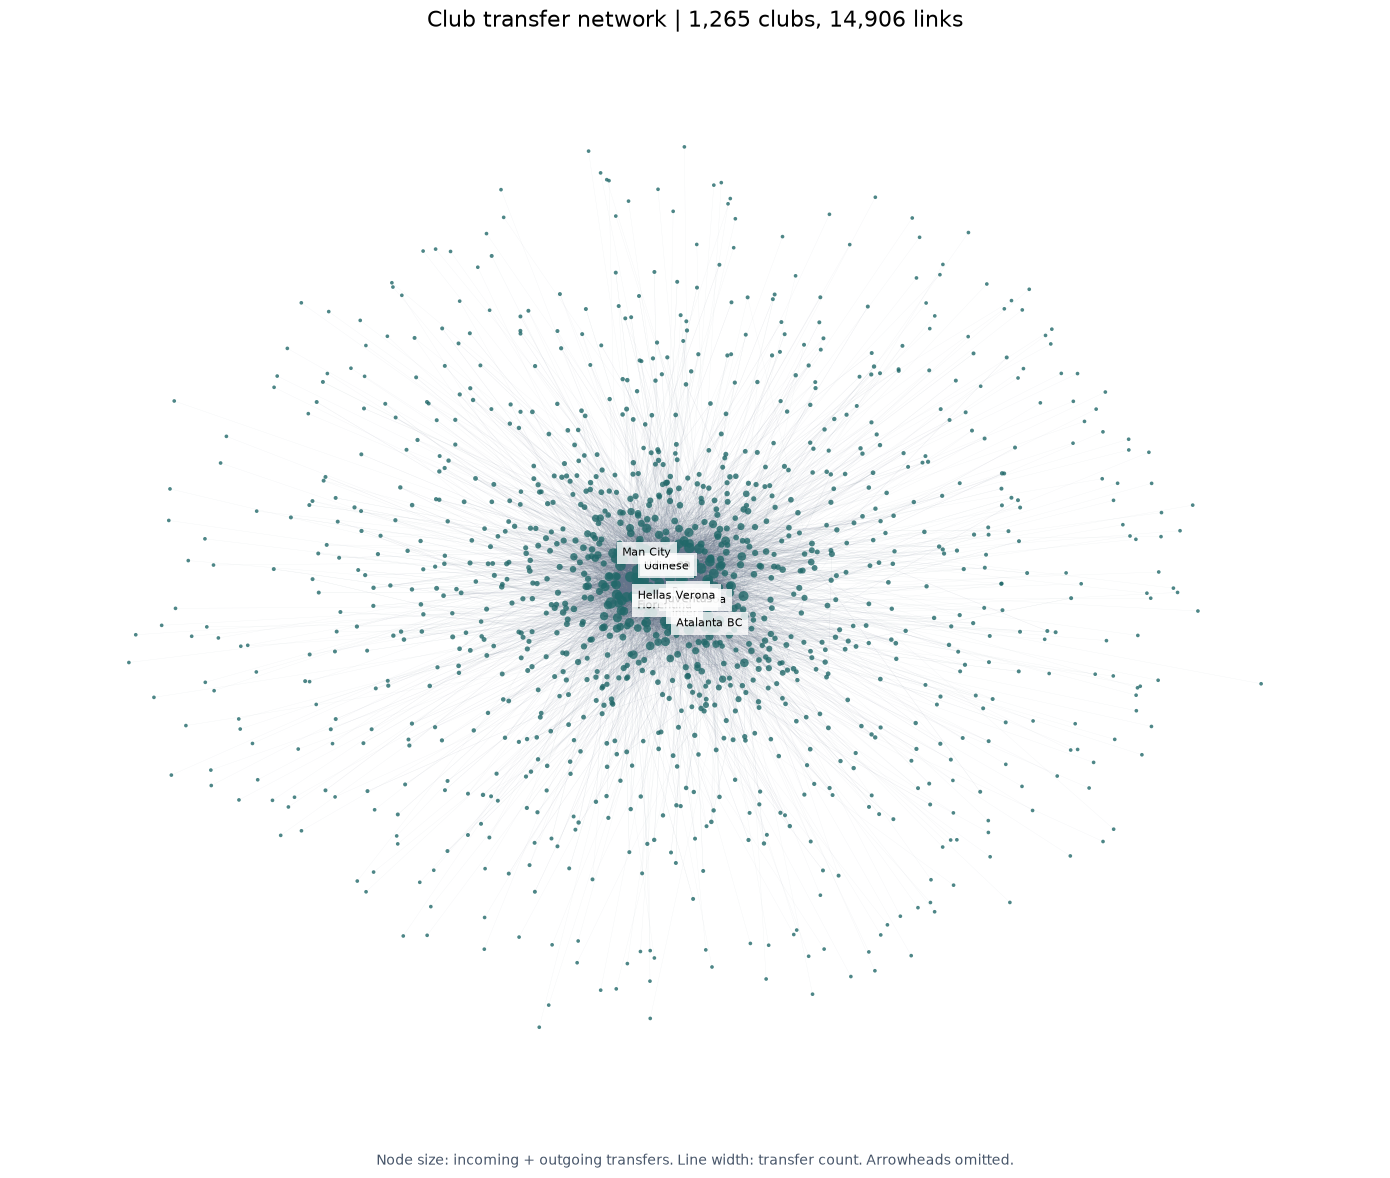

In [46]:
import matplotlib.pyplot as plt
import numpy as np

strength = dict(graph.degree(weight='weight'))
pos = nx.spring_layout(graph, seed=42, weight='weight', iterations=30)

fig, ax = plt.subplots(figsize=(14, 12))
nx.draw_networkx_edges(
    graph, pos, ax=ax, arrows=False, edge_color='#64748b', alpha=0.08,
    width=[0.15 + 0.15 * np.log1p(edge['weight']) for _, _, edge in graph.edges(data=True)],
)
nx.draw_networkx_nodes(
    graph, pos, ax=ax, node_size=[4 + 3 * np.sqrt(strength[node]) for node in graph],
    node_color='#216869', alpha=0.8, linewidths=0,
)
top_clubs = sorted(strength, key=strength.get, reverse=True)[:10]
nx.draw_networkx_labels(
    graph, pos, ax=ax, labels={node: graph.nodes[node]['label'] for node in top_clubs},
    font_size=8, bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.8},
)
ax.set_title(
    f'Club transfer network | {graph.number_of_nodes():,} clubs, {graph.number_of_edges():,} links',
    fontsize=16, pad=20,
)
ax.set_axis_off()
fig.text(
    0.5, 0.025,
    'Node size: incoming + outgoing transfers. Line width: transfer count. Arrowheads omitted.',
    ha='center', fontsize=10, color='#475569',
)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()